# Godot: custom-type nodes, and when to use them

A **custom-type node** is a node whose type is defined by a script with `class_name`.
It appears in the Create Node dialog like a built-in node, and in the scene tree its script icon is **dimmed**.

| Script icon | Name | Meaning |
|---|---|---|
| Solid | Attached script | A plain node that had a script attached to it |
| Dimmed | Custom type | The script *is* the node's type |
| Blue tint | `@tool` script | The script is running inside the editor (can combine with either) |

At runtime a custom-type node and a plain node with the same script attached behave identically.
The difference is how you create it and how the editor treats it.

## 1. Three ways to make a node

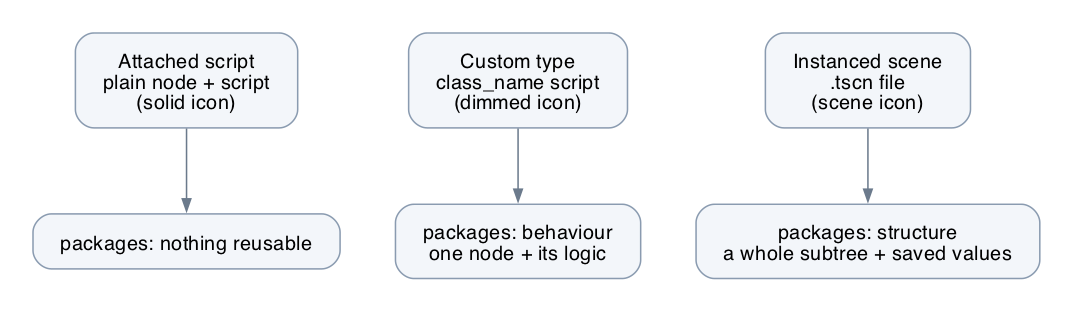

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  rankdir=TB;
  a [label="Attached script\nplain node + script\n(solid icon)"];
  b [label="Custom type\nclass_name script\n(dimmed icon)"];
  c [label="Instanced scene\n.tscn file\n(scene icon)"];
  x [label="packages: nothing reusable"];
  y [label="packages: behaviour\none node + its logic"];
  z [label="packages: structure\na whole subtree + saved values"];
  a -> x; b -> y; c -> z;
}
```

</details>

| | Attached script | Custom type | Instanced scene |
|---|---|---|---|
| **How you make it** | Add a base node, attach a script | Pick your class in Create Node | Drag in / instance a `.tscn` |
| **In code** | — | `MyType.new()` | `preload("x.tscn").instantiate()` |
| **Has children?** | Whatever you add by hand | No (unless the script builds them) | Yes, laid out in the editor |
| **Where defaults live** | Script | Script (`@export` defaults) | Saved in the scene file |
| **Usable as a type** (`is`, type hints) | Only if it has `class_name` | Yes | Only if the root script has `class_name` |
| **Good for** | One-off logic | Reusable single-node building blocks | Anything made of several nodes |

## 2. Which one should I use?

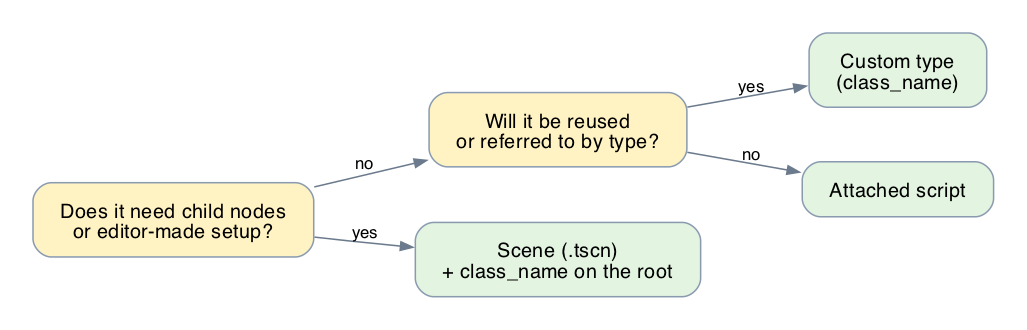

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  q1 [label="Does it need child nodes\nor editor-made setup?", fillcolor="#fff3c4"];
  q2 [label="Will it be reused\nor referred to by type?", fillcolor="#fff3c4"];
  s  [label="Scene (.tscn)\n+ class_name on the root", fillcolor="#e3f4e1"];
  c  [label="Custom type\n(class_name)", fillcolor="#e3f4e1"];
  a  [label="Attached script", fillcolor="#e3f4e1"];
  q1 -> s  [label="yes"];
  q1 -> q2 [label="no"];
  q2 -> c  [label="yes"];
  q2 -> a  [label="no"];
}
```

</details>

| Use | When | Examples of that shape |
|---|---|---|
| **Custom type** | One node, and its value is its logic: helpers, components, data holders, base classes | A lambda / action node, a turn, a mover component |
| **Scene** | It needs children, or values you want to tune in the Inspector | A player with sprite + collision, a UI panel, a whole game viewport |
| **Scene + `class_name` on the root** | It is a scene, *and* code needs to talk about it as a type | A viewport scene whose root extends `_Core_Viewport` |
| **Attached script** | Logic that belongs to exactly one node in one scene | Glue code on a specific button |

### In this repo

| Class | Shape | Why |
|---|---|---|
| `_Core_Lambdas` (`extends Node`) | Custom type | A single node of pure logic |
| `_Core_Turn` and its subclasses | Custom type | Single-node building blocks, picked by type |
| `_Core_Viewport` | Scene + `class_name` | Every game scene needs a child named exactly `SubViewport`, so it must come from a `.tscn`; the class gives the shared lifecycle and the type |

## 3. The one trap

A `class_name` makes a type creatable **without its scene**. If the script expects children, that bare node is broken.

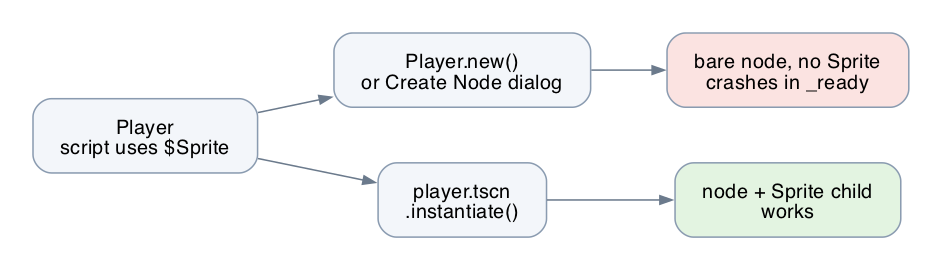

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  t  [label="Player\nscript uses $Sprite"];
  n  [label="Player.new()\nor Create Node dialog"];
  i  [label="player.tscn\n.instantiate()"];
  bad  [label="bare node, no Sprite\ncrashes in _ready", fillcolor="#fbe3e1"];
  good [label="node + Sprite child\nworks", fillcolor="#e3f4e1"];
  t -> n -> bad;
  t -> i -> good;
}
```

</details>

Rule of thumb: **if the script uses `$Child` or `@onready` child paths, only ever create it from its scene.**

The cell below imitates this in Python so you can see both paths.

In [ ]:
class Node:
    def __init__(self, name): self.name, self.children = name, {}
    def add_child(self, c):   self.children[c.name] = c
    def get(self, path):
        if path not in self.children:
            raise LookupError(f"Node not found: '{path}' (relative to '{self.name}')")
        return self.children[path]

class Player(Node):                       # like: class_name Player
    def _ready(self):
        sprite = self.get("Sprite")       # like: $Sprite
        print(f"  {self.name} ready, found {sprite.name}")

def player_scene():                       # like: player.tscn
    p = Player("Player")
    p.add_child(Node("Sprite"))
    return p

def try_ready(label, node):
    print(label)
    try:    node._ready()
    except LookupError as e: print("  ERROR:", e)

try_ready("player.tscn .instantiate()", player_scene())
try_ready("Player.new()", Player("Player"))

player.tscn .instantiate()
  Player ready, found Sprite
Player.new()
  ERROR: Node not found: 'Sprite' (relative to 'Player')


In [ ]:
# ----- student scratchpad ----- 


## 4. Smaller things worth knowing

| Topic | Note |
|---|---|
| Detaching | A custom-type node hides the "detach script" button — the script is its identity. Use *Change Type* instead |
| Icon | Add `@icon("res://path.svg")` above `class_name` to give the type its own icon in the tree and Create Node dialog |
| Names are global | `class_name` registers project-wide, so every name must be unique |
| Not just nodes | `class_name` on a script that `extends Resource` gives a custom **resource** type — the right tool for pure data edited in the Inspector |
| Plugin custom types | An `EditorPlugin` can also register types with `add_custom_type()`; `class_name` is the simpler, usual route |

## 5. Cheat sheet

| I want... | Use |
|---|---|
| A reusable node that is just logic | Custom type |
| A reusable thing made of several nodes | Scene |
| A scene that code can type-check and type-hint | Scene + `class_name` on its root |
| A shared base class for many scenes | `class_name` base script, each scene's root extends it |
| Data, not behaviour | Custom `Resource` |
| Logic for one specific node | Attached script |